# Лабораторная работа 4. Многомерная бинарная классификация

Датасет: `datasets/student.csv`. Предсказываем `G3`.

In [1]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

import warnings

warnings.filterwarnings('ignore', category=RuntimeWarning)

df = pd.read_csv('student.csv')
df = df.drop(columns=["Unnamed: 0"])

y = df["G3"]
X = df.drop(columns=["G3"])

print(df.dtypes)

school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G3             int64
dtype: object


# Задание 1
Предобработайте данные. Для числовых признаков используйте стандартизацию, для категориальных - one-hot-кодирование. Разделите выборку на обучающую и тестовую. Размер выборок выберите самостоятельно.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=666,
    stratify=y
)

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Train:", X_train_processed.shape)
print("Test:", X_test_processed.shape)

print("\nclasses G3:")
print(y.value_counts())

Train: (316, 56)
Test: (79, 56)

classes G3:
G3
1    209
0    186
Name: count, dtype: int64


# Задание 2

Обучите следующие модели:
1. SVM
2. Логистическая регрессия
3. KNN
4. Дерево решений

Подберите оптимальные гиперпараметры с помощью кросс-валидации

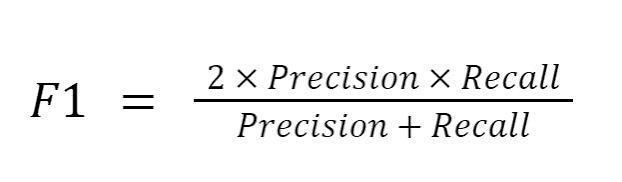 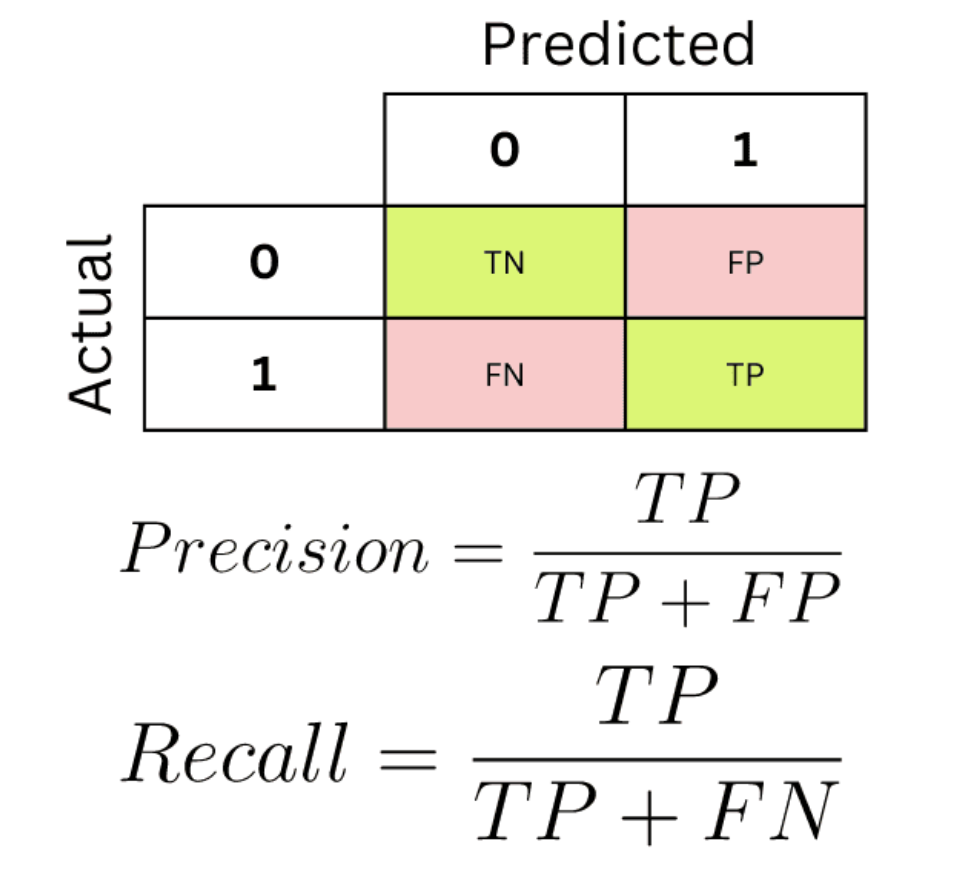 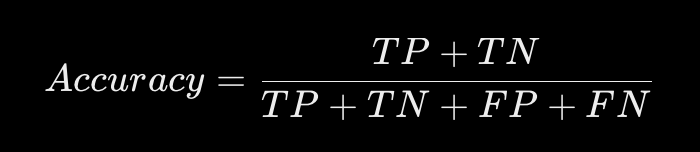

In [3]:
from sklearn.model_selection import GridSearchCV

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

#1
svm_params = {
    "C": [0.1, 1, 10],
    "kernel": ["linear", "rbf"],
    "gamma": ["scale", "auto"]
}

svm_grid = GridSearchCV(
    SVC(),
    svm_params,
    cv=5,
    scoring="f1"
)

svm_grid.fit(X_train_processed, y_train)

print("SVM:")
print("Best params:", svm_grid.best_params_)
print("Best CV F1:", svm_grid.best_score_)


SVM:
Best params: {'C': 0.1, 'gamma': 'auto', 'kernel': 'rbf'}
Best CV F1: 0.6929290641921446


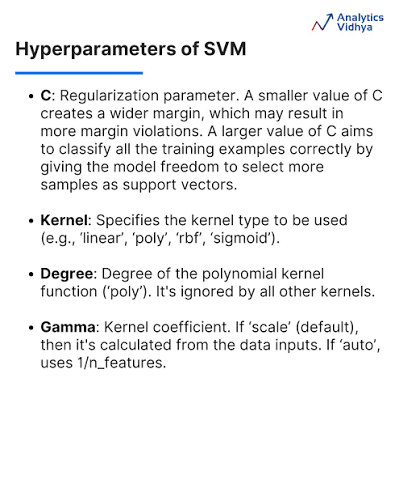 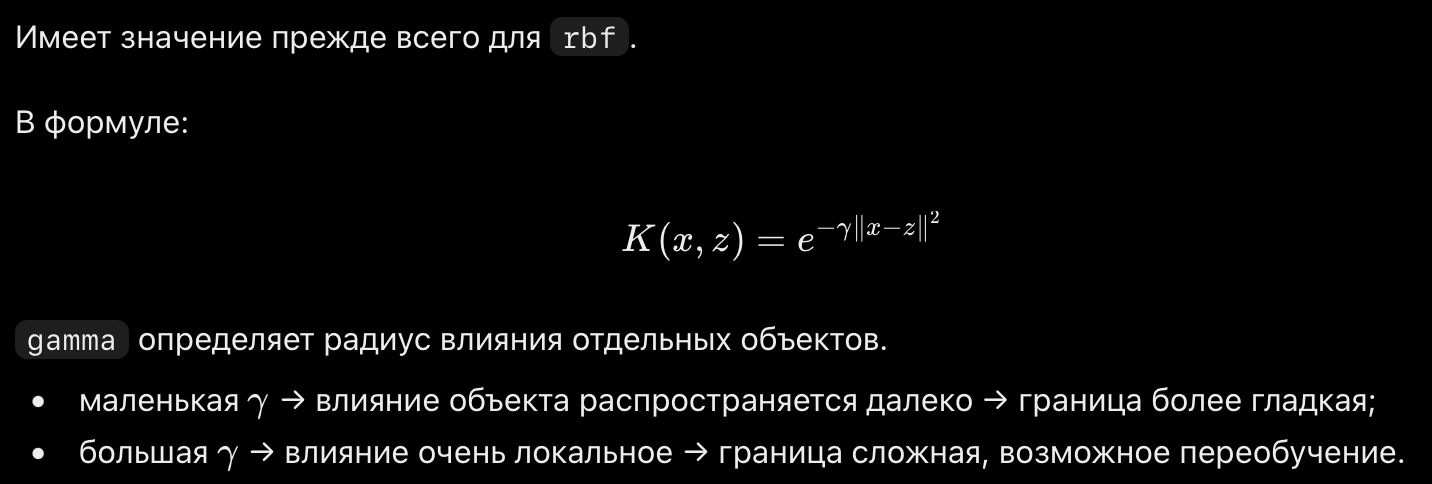 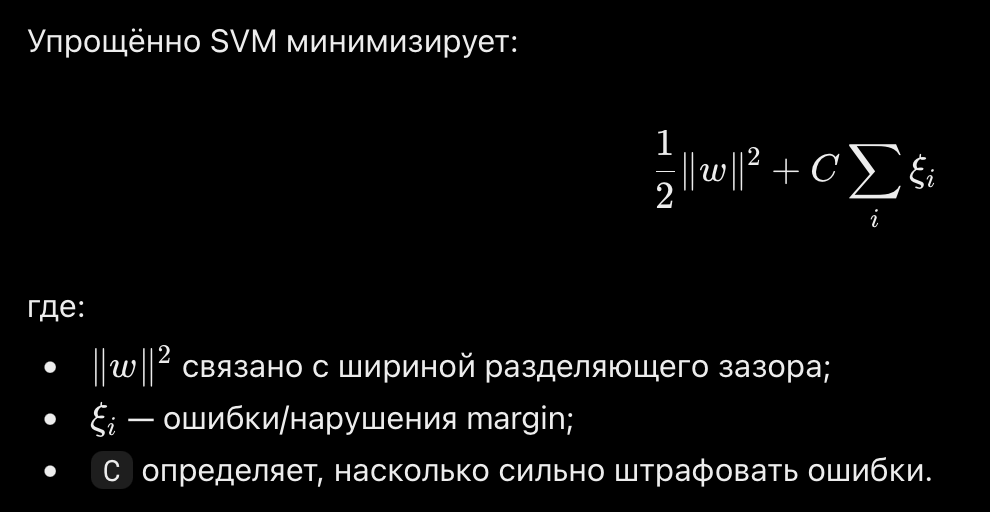 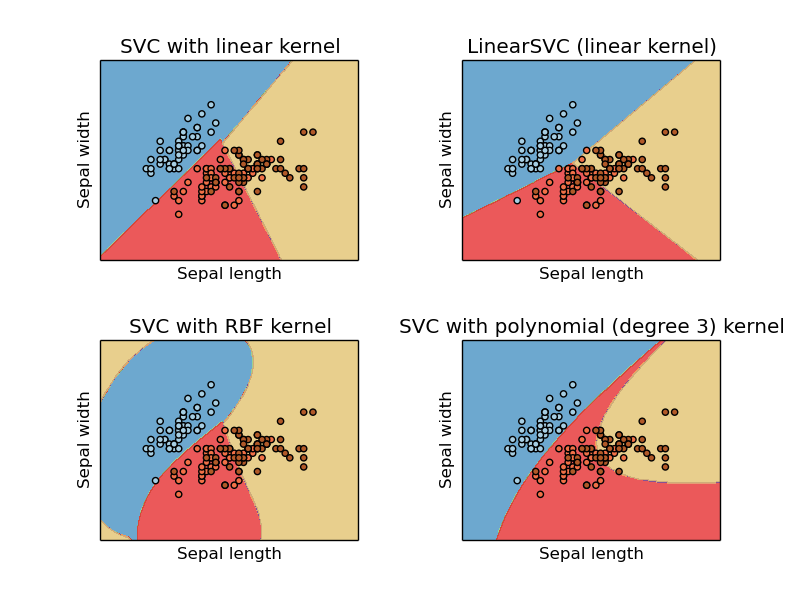

In [4]:
#2
logreg_params = {
    "C": [0.01, 0.1, 1, 10, 100]
}

logreg_grid = GridSearchCV(
    LogisticRegression(max_iter=1000),
    logreg_params,
    cv=5,
    scoring="f1"
)

logreg_grid.fit(X_train_processed, y_train)

print("Logistic Regression:")
print("Best params:", logreg_grid.best_params_)
print("Best CV F1:", logreg_grid.best_score_)

Logistic Regression:
Best params: {'C': 0.1}
Best CV F1: 0.6645463550204551


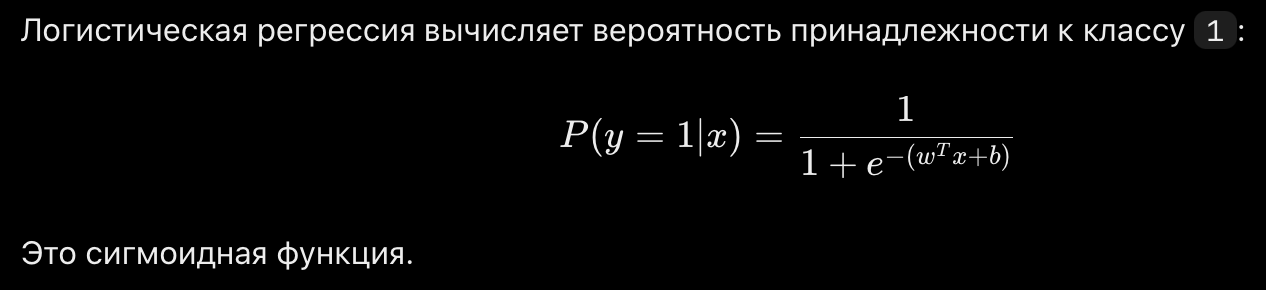 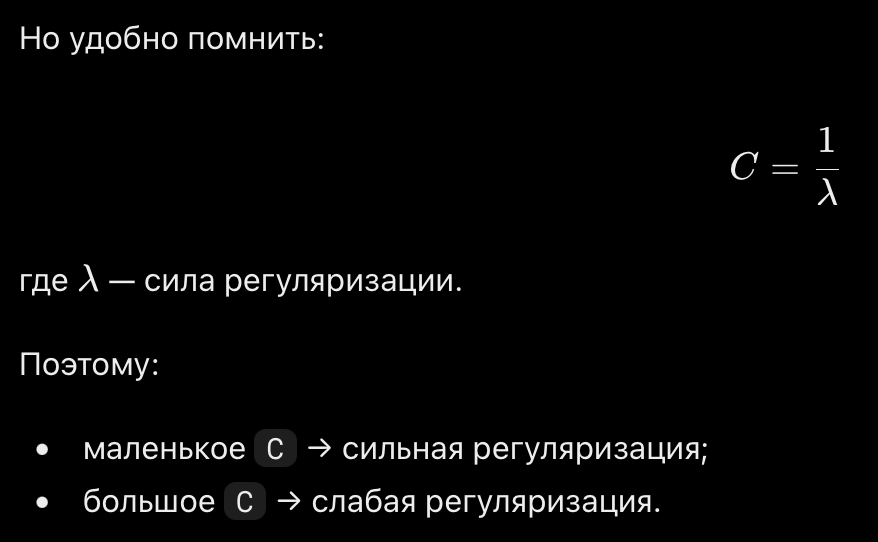

In [5]:
#3
knn_params = {
    "n_neighbors": [3, 5, 7, 9, 11],
    "weights": ["uniform", "distance"],
    "p": [1, 2]
}

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    knn_params,
    cv=5,
    scoring="f1"
)

knn_grid.fit(X_train_processed, y_train)

print("KNN:")
print("Best params:", knn_grid.best_params_)
print("Best CV F1:", knn_grid.best_score_)

KNN:
Best params: {'n_neighbors': 11, 'p': 2, 'weights': 'uniform'}
Best CV F1: 0.6289026008349424


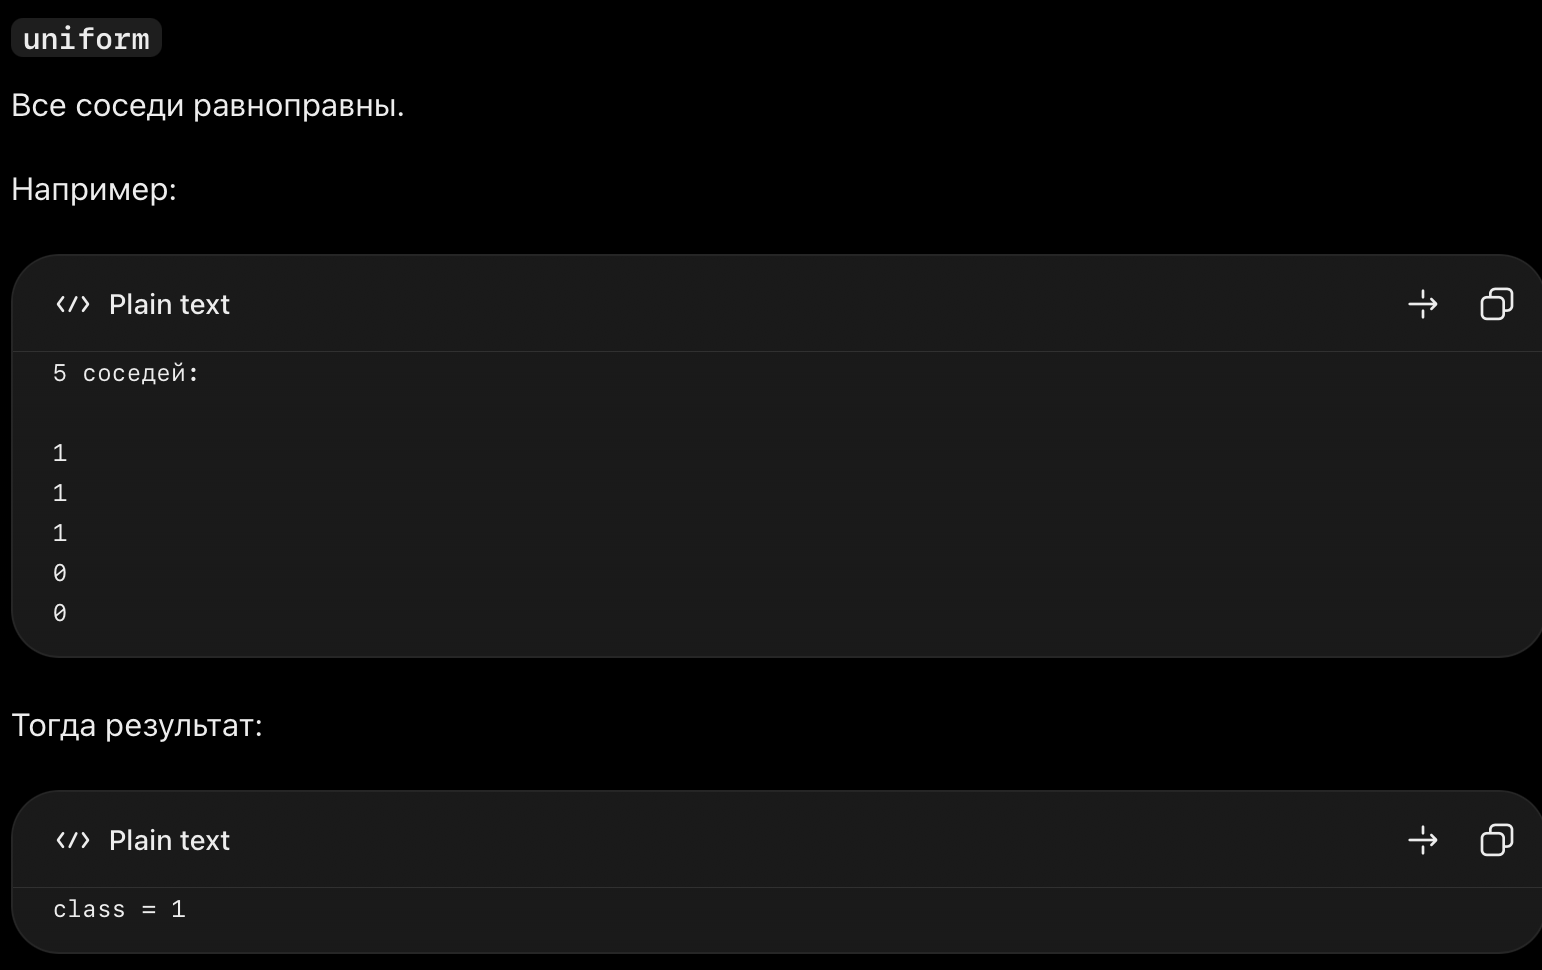 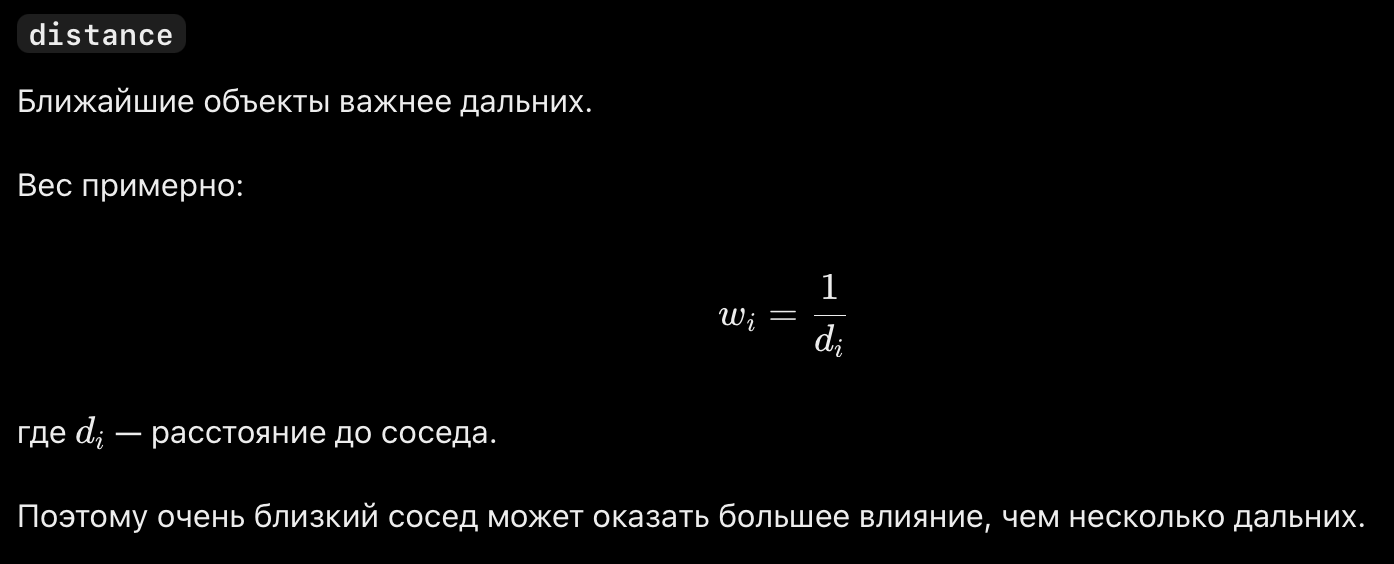 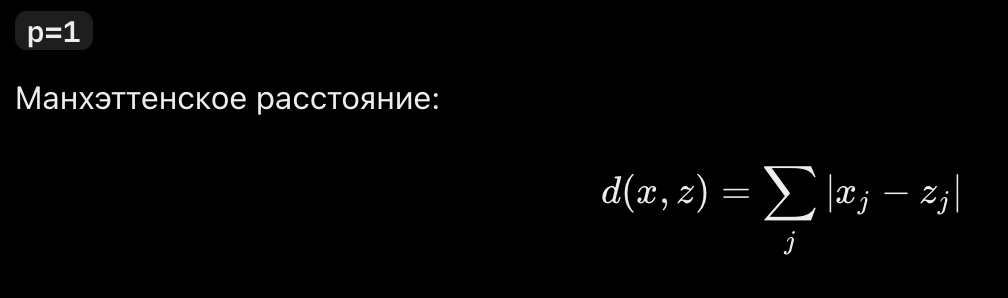 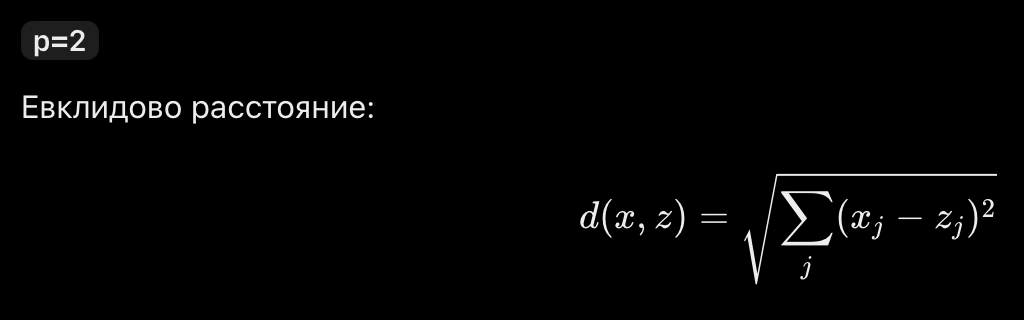

In [6]:
#4
tree_params = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 3, 5, 7, 10],
    "min_samples_split": [2, 5, 10], #Минимальное количество объектов в узле, чтобы его вообще разрешалось разделить
    "min_samples_leaf": [1, 2, 4]  #Минимальное количество объектов, которое должно остаться в каждом листе
}

tree_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    tree_params,
    cv=5,
    scoring="f1"
)

tree_grid.fit(X_train_processed, y_train)

print("Decision Tree:")
print("Best params:", tree_grid.best_params_)
print("Best CV F1:", tree_grid.best_score_)

Decision Tree:
Best params: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 4, 'min_samples_split': 2}
Best CV F1: 0.634107153405399


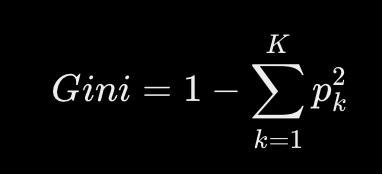 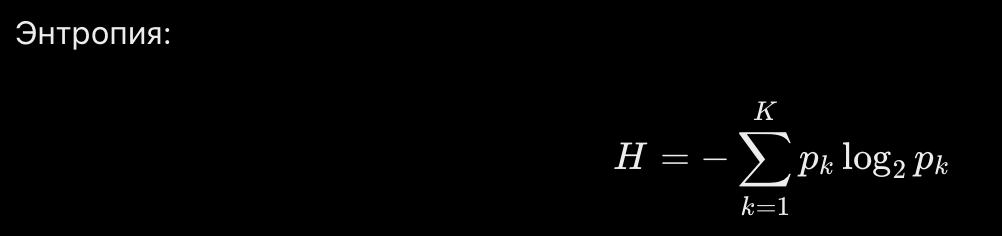

# Задание 3

Для каждой модели посчитайте Accuracy, Precision, Recall, F1-score. Постройте confusion matrix и roc-кривую.

In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

import matplotlib.pyplot as plt

best_models = {
    "SVM": svm_grid.best_estimator_,
    "Logistic Regression": logreg_grid.best_estimator_,
    "KNN": knn_grid.best_estimator_,
    "Decision Tree": tree_grid.best_estimator_
}

for name, model in best_models.items():
    y_pred = model.predict(X_test_processed)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print(name)
    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1-score:", f1)
    print()

SVM
Accuracy: 0.569620253164557
Precision: 0.5526315789473685
Recall: 1.0
F1-score: 0.711864406779661

Logistic Regression
Accuracy: 0.6582278481012658
Precision: 0.6595744680851063
Recall: 0.7380952380952381
F1-score: 0.6966292134831461

KNN
Accuracy: 0.6075949367088608
Precision: 0.6122448979591837
Recall: 0.7142857142857143
F1-score: 0.6593406593406593

Decision Tree
Accuracy: 0.6708860759493671
Precision: 0.6333333333333333
Recall: 0.9047619047619048
F1-score: 0.7450980392156863



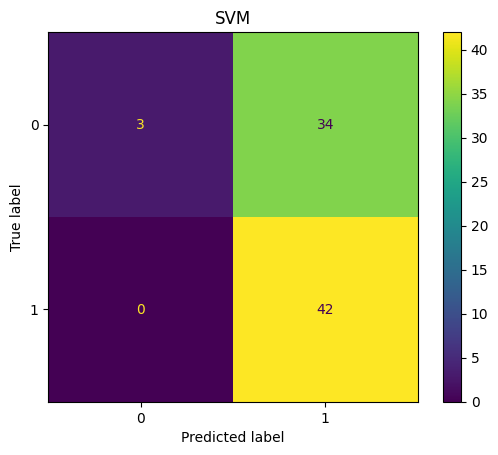

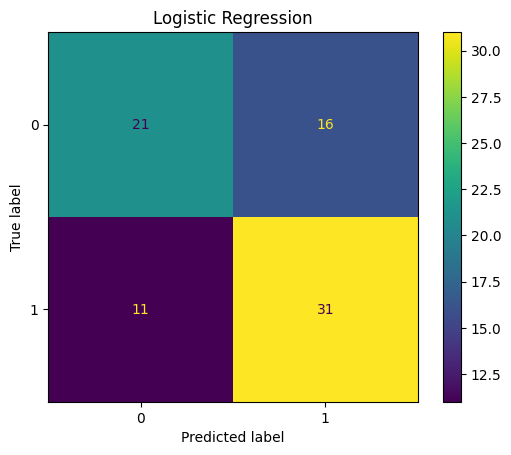

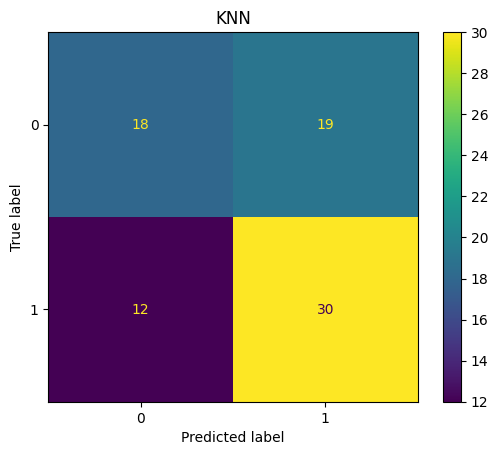

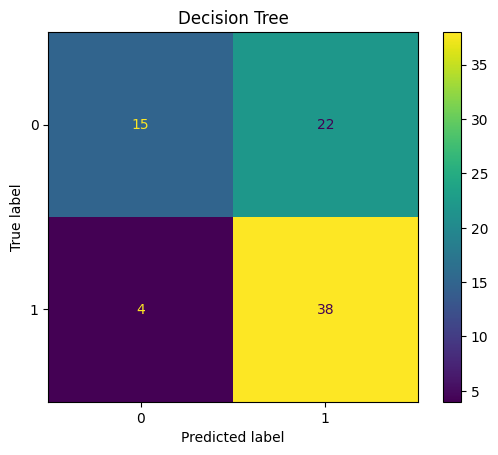

In [8]:
for name, model in best_models.items():
    y_pred = model.predict(X_test_processed)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred
    )

    plt.title(name)
    plt.show()

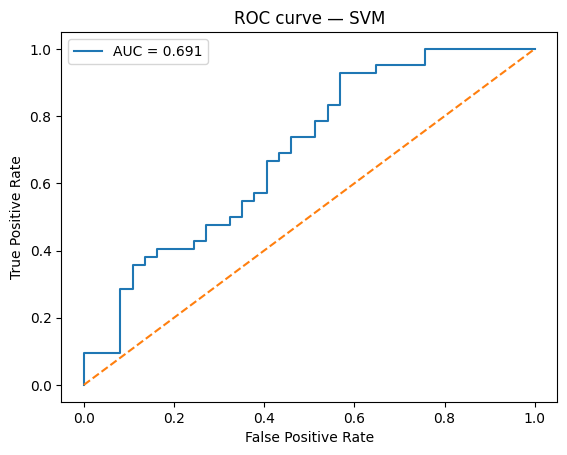

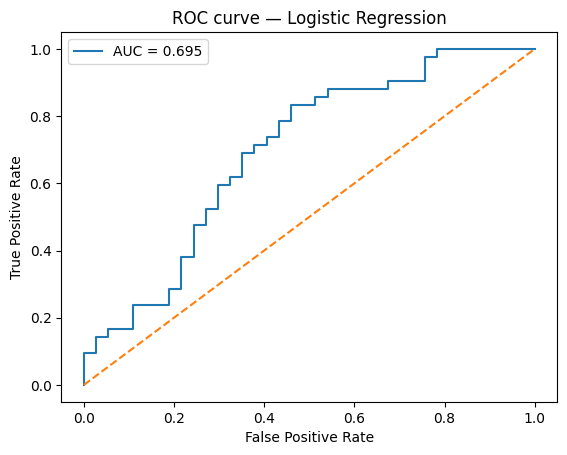

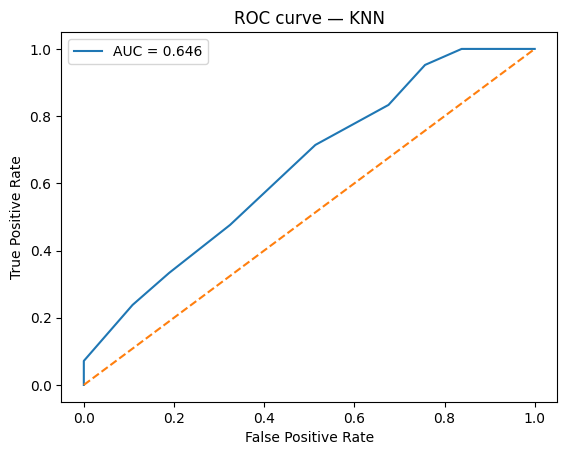

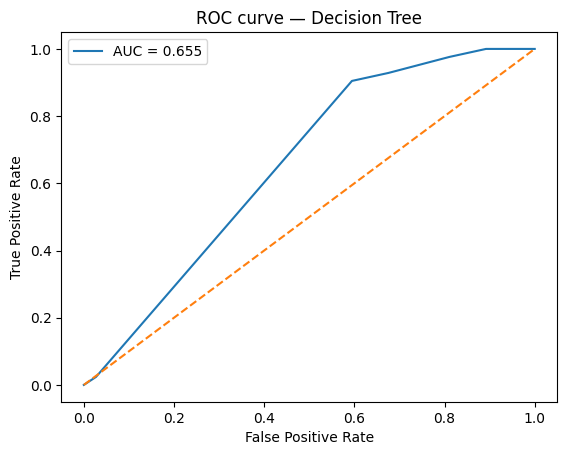

In [9]:
for name, model in best_models.items():

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_processed)[:, 1]
    else:
        y_score = model.decision_function(X_test_processed)

    fpr, tpr, thresholds = roc_curve(y_test, y_score)
    auc = roc_auc_score(y_test, y_score)

    plt.figure()

    plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
    plt.plot([0, 1], [0, 1], "--")

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC curve — {name}")
    plt.legend()

    plt.show()

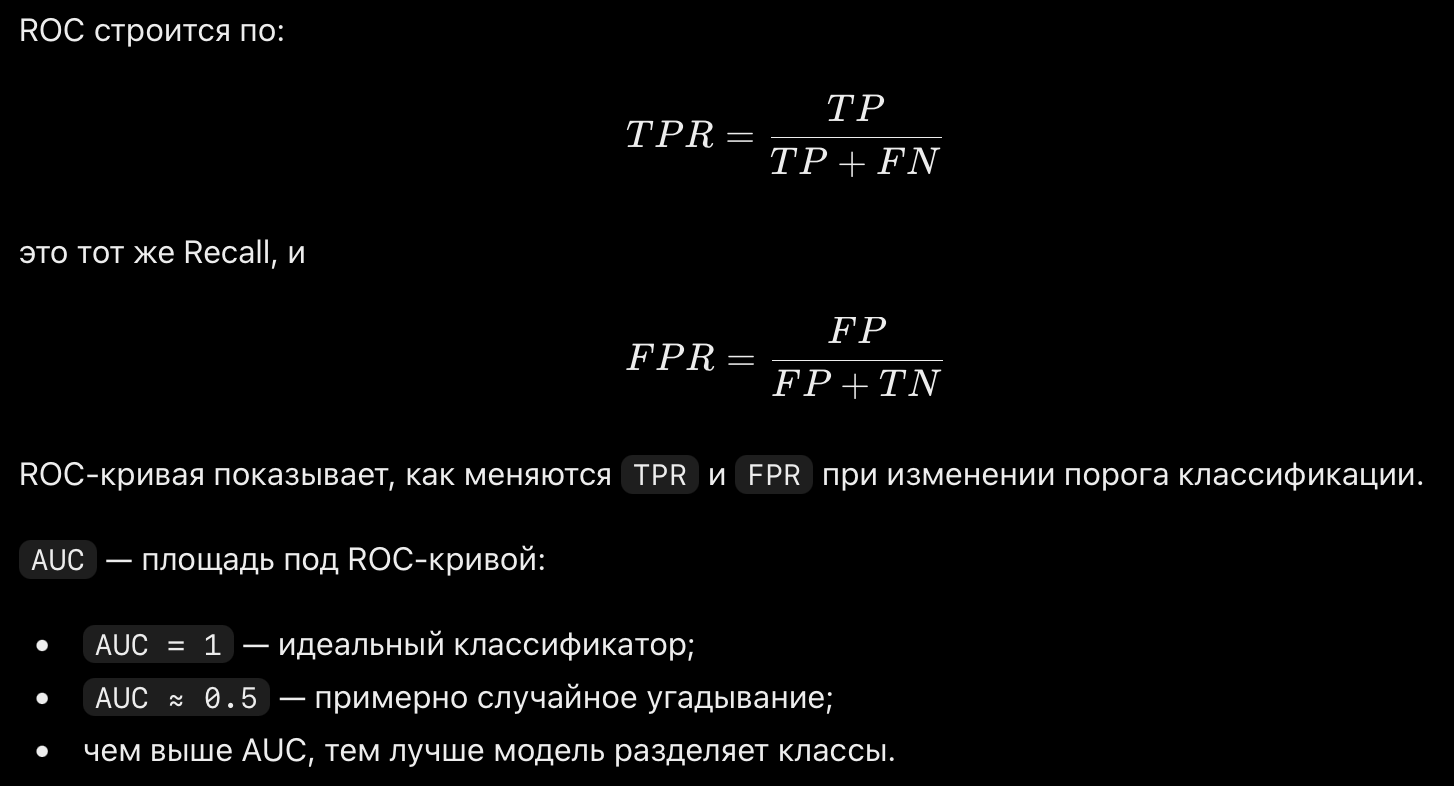

# Задание 4

Для логистической регрессии выберите оптимальный порог классификации. Постройте график зависимости метрик от порога классификации. Сравнить качество модели при оптимальном пороге и пороге равном 0.5.

Best threshold: 0.4299999999999998
Best F1: 0.7474747474747475


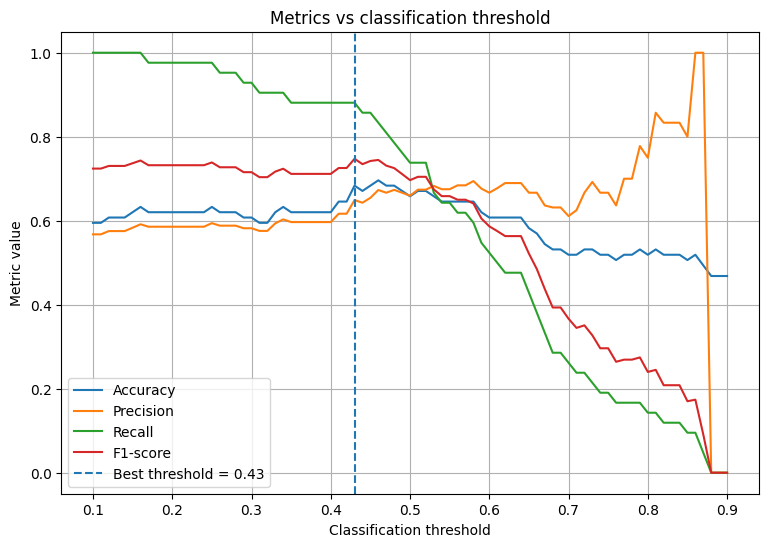

In [10]:
import numpy as np

logreg_best = logreg_grid.best_estimator_

y_proba = logreg_best.predict_proba(X_test_processed)[:, 1]

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(0.1, 0.91, 0.01)

results = []

for threshold in thresholds:
    y_pred = (y_proba >= threshold).astype(int)

    results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred)
    })

threshold_results = pd.DataFrame(results)

best_row = threshold_results.loc[
    threshold_results["f1"].idxmax()
]

best_threshold = best_row["threshold"]

print("Best threshold:", best_threshold)
print("Best F1:", best_row["f1"])

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_results["threshold"],
    threshold_results["accuracy"],
    label="Accuracy"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["precision"],
    label="Precision"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["recall"],
    label="Recall"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["f1"],
    label="F1-score"
)

plt.axvline(
    x=best_threshold,
    linestyle="--",
    label=f"Best threshold = {best_threshold:.2f}"
)

plt.xlabel("Classification threshold")
plt.ylabel("Metric value")
plt.title("Metrics vs classification threshold")

plt.legend()
plt.grid()

plt.show()